Identifikasi dataset:

Jenis Klasifikasi: Multiclass Classification
- Independent Variables: Karakteristik fisik beras, seperti Area, Major Axis Length, Minor Axis Length, Eccentricity, Convex Area, dan Extent apabila tersedia dalam CSV
- Dependent Variable: Kolom kelas atau jenis beras
- Jumlah Independent Variables: Mengikuti jumlah fitur pada dataset setelah kolom identitas dikeluarkan
- Jumlah Dependent Variables: 1 target
- Jumlah Kategori Target: Lebih dari dua kategori
- Tujuan: Mengidentifikasi jenis beras berdasarkan karakteristik fisiknya

Penjelasan variabel:

1. Area: Menggambarkan luas permukaan butiran beras.
2. Major Axis Length: Menggambarkan panjang sumbu utama butiran beras.
3. Minor Axis Length: Menggambarkan panjang sumbu pendek butiran beras.
4. Eccentricity: Menggambarkan tingkat kelonjongan bentuk butiran beras.
5. Convex Area: Menggambarkan luas area cembung yang membungkus bentuk butiran beras.
6. Extent: Menggambarkan perbandingan luas butiran dengan luas kotak pembatasnya.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer

In [2]:
df = pd.read_csv("riceClassification.csv")

In [3]:
print("=== IDENTIFIKASI DATASET RICE TYPE ===")

print("\nInformasi Dataset:")
df.info()

print("\nJumlah Baris dan Kolom:")
print(df.shape)

print("\nNama Kolom:")
print(df.columns.tolist())

print("\nLima Data Pertama:")
print(df.head())

=== IDENTIFIKASI DATASET RICE TYPE ===

Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 18185 entries, 0 to 18184
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               18185 non-null  int64  
 1   Area             18185 non-null  int64  
 2   MajorAxisLength  18185 non-null  float64
 3   MinorAxisLength  18185 non-null  float64
 4   Eccentricity     18185 non-null  float64
 5   ConvexArea       18185 non-null  int64  
 6   EquivDiameter    18185 non-null  float64
 7   Extent           18185 non-null  float64
 8   Perimeter        18185 non-null  float64
 9   Roundness        18185 non-null  float64
 10  AspectRation     18185 non-null  float64
 11  Class            18185 non-null  int64  
dtypes: float64(8), int64(4)
memory usage: 1.7 MB

Jumlah Baris dan Kolom:
(18185, 12)

Nama Kolom:
['id', 'Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'EquivDiameter',

In [4]:
target = "Class"

id_columns = [
    col for col in df.columns
    if col.lower() in ["id", "no"]
]

X = df.drop(columns=[target] + id_columns)
y = df[target]

print("\nIndependent Variables:")
print(X.columns.tolist())

print("\nDependent Variable:")
print(target)

print("\nJumlah Independent Variables:", X.shape[1])
print("Jumlah Dependent Variables:", 1)

print("\nJumlah Kategori Target:")
print(y.nunique())

print("\nDistribusi Target:")
print(y.value_counts())

print("\nIdentifikasi Klasifikasi:")
if y.nunique() > 2:
    print("Multiclass Classification")
else:
    print("Binary Classification")


Independent Variables:
['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Perimeter', 'Roundness', 'AspectRation']

Dependent Variable:
Class

Jumlah Independent Variables: 10
Jumlah Dependent Variables: 1

Jumlah Kategori Target:
2

Distribusi Target:
Class
1    9985
0    8200
Name: count, dtype: int64

Identifikasi Klasifikasi:
Binary Classification



=== EXPLORATORY DATA ANALYSIS (EDA) ===

Statistik Deskriptif:
                 id          Area  MajorAxisLength  MinorAxisLength  \
count  18185.000000  18185.000000     18185.000000     18185.000000   
mean    9093.000000   7036.492989       151.680754        59.807851   
std     5249.701658   1467.197150        12.376402        10.061653   
min        1.000000   2522.000000        74.133114        34.409894   
25%     4547.000000   5962.000000       145.675910        51.393151   
50%     9093.000000   6660.000000       153.883750        55.724288   
75%    13639.000000   8423.000000       160.056214        70.156593   
max    18185.000000  10210.000000       183.211434        82.550762   

       Eccentricity    ConvexArea  EquivDiameter        Extent     Perimeter  \
count  18185.000000  18185.000000   18185.000000  18185.000000  18185.000000   
mean       0.915406   7225.817872      94.132952      0.616653    351.606949   
std        0.030575   1502.006571       9.906250      0.

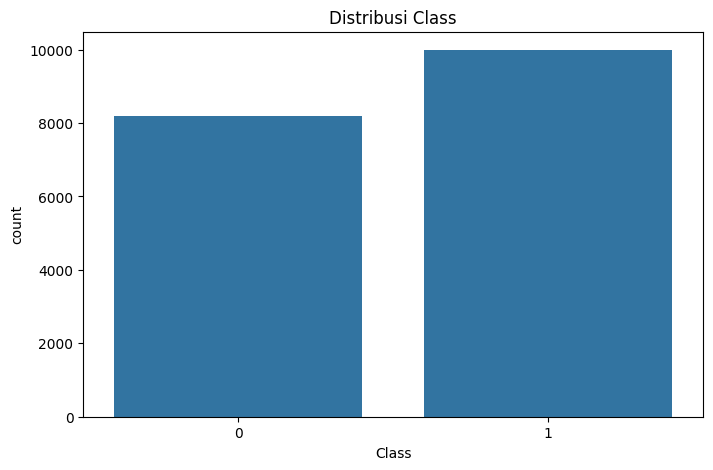

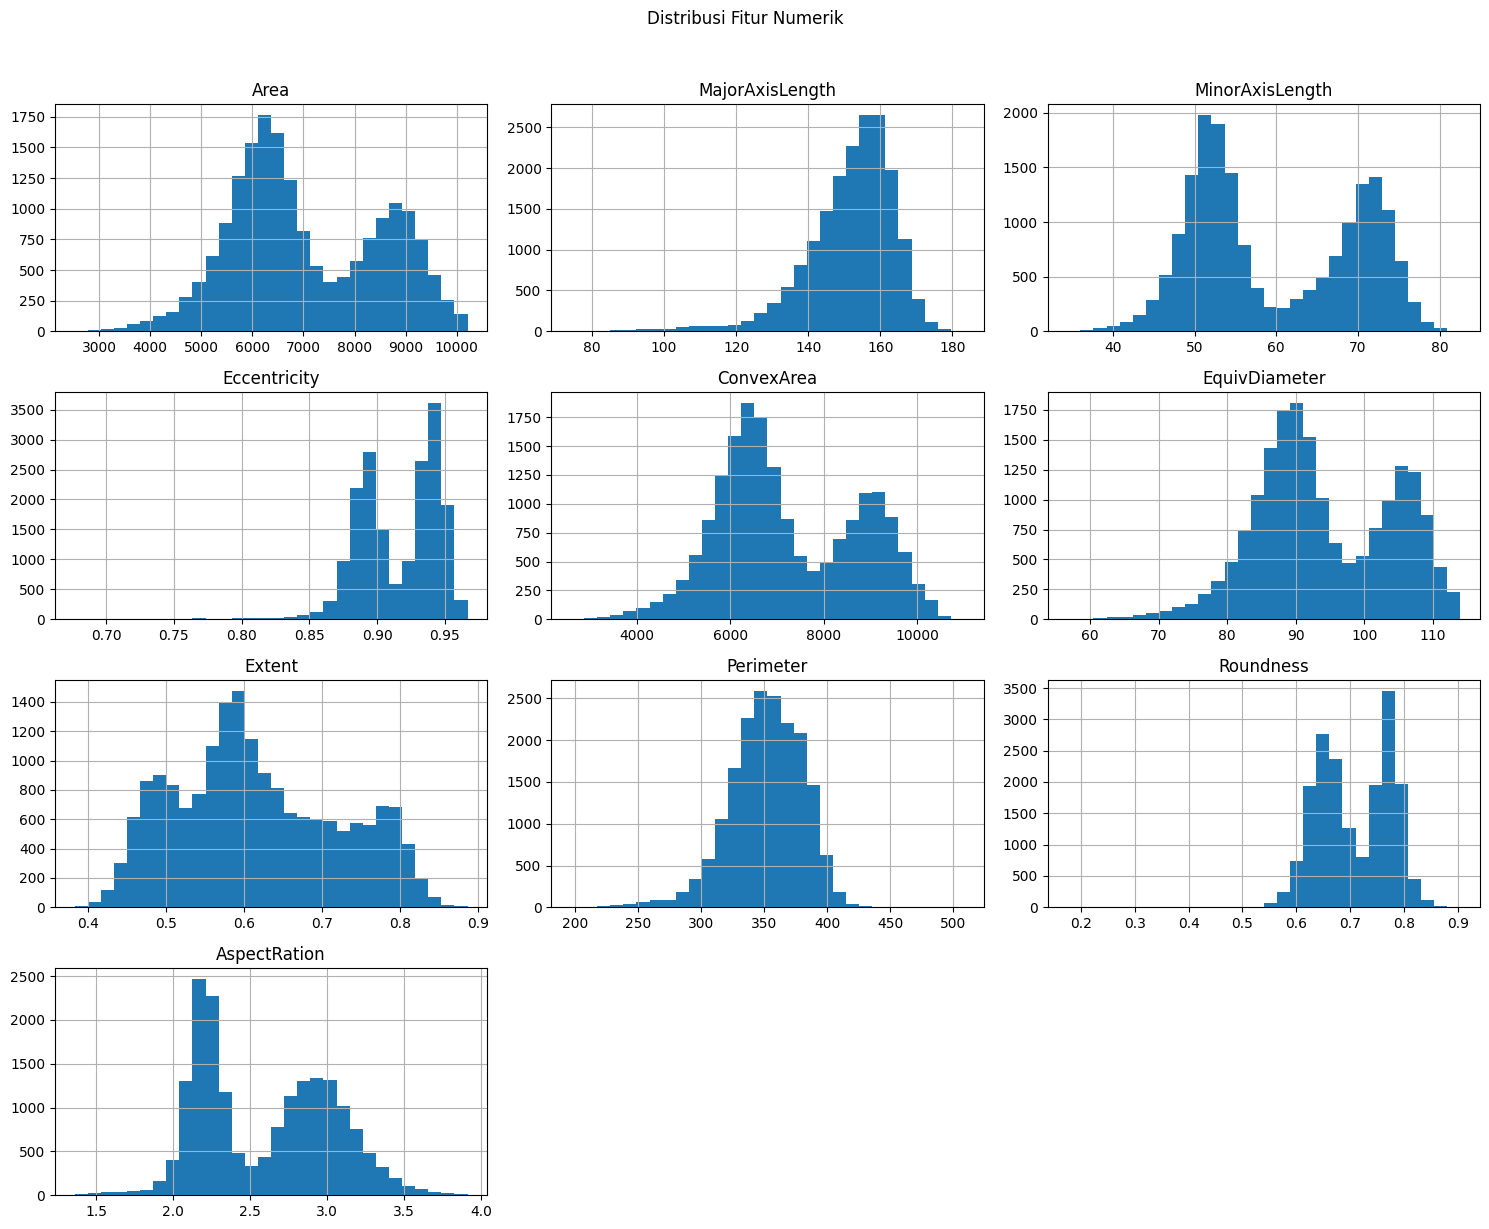

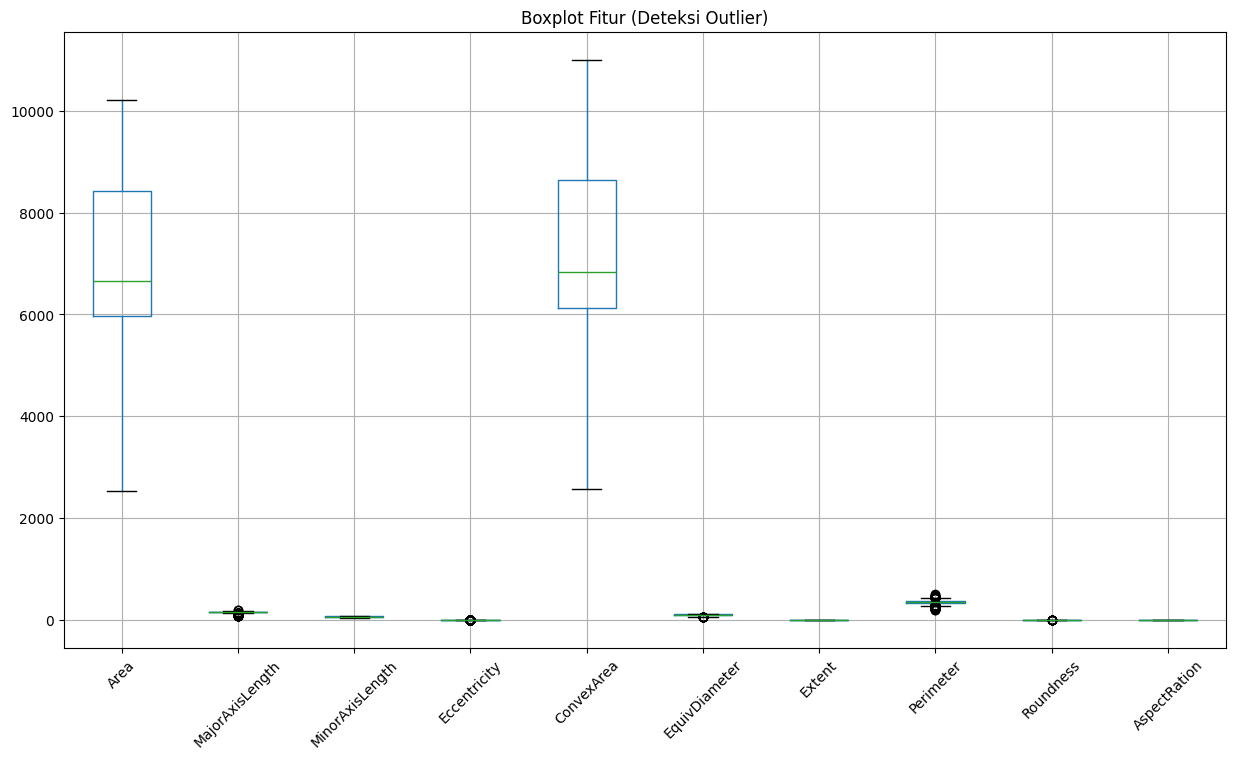

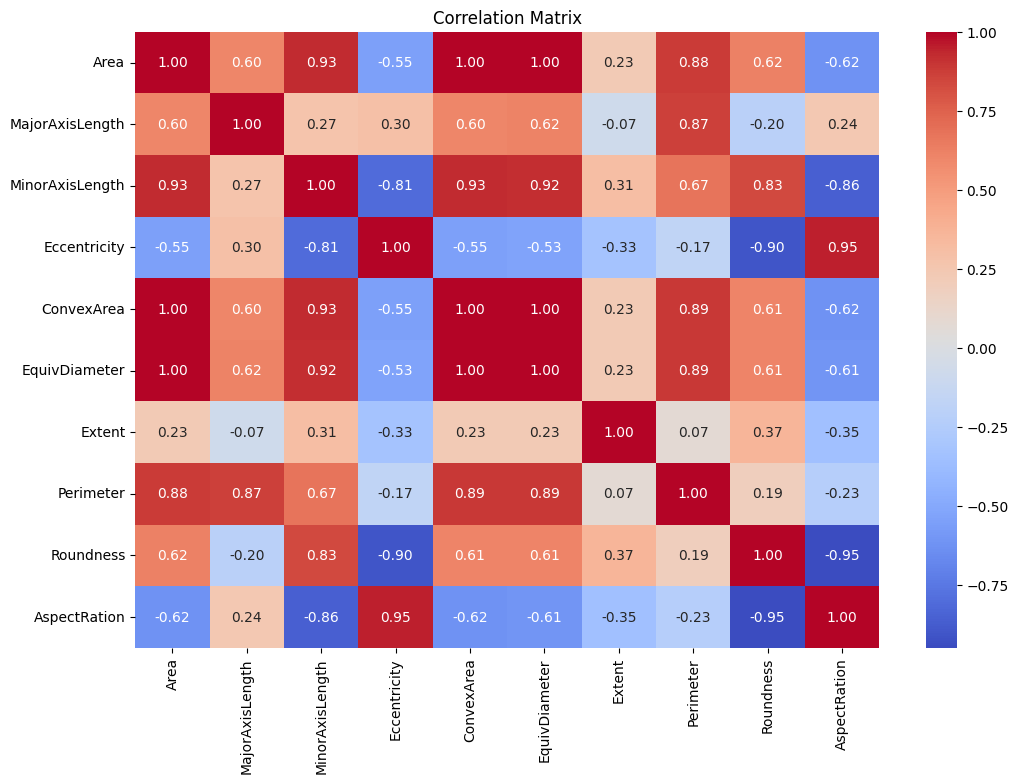

In [5]:
print("\n=== EXPLORATORY DATA ANALYSIS (EDA) ===")

# Statistik Deskriptif
print("\nStatistik Deskriptif:")
print(df.describe())

# Cek Missing Value
print("\nMissing Values:")
print(df.isnull().sum())

# Cek Data Duplikat
print("\nJumlah Data Duplikat:", df.duplicated().sum())

# Distribusi Target
plt.figure(figsize=(8, 5))
sns.countplot(x=y)
plt.title("Distribusi Class")
plt.show()

# Histogram Fitur Numerik
X.hist(figsize=(15, 12), bins=30)
plt.suptitle("Distribusi Fitur Numerik", y=1.02)
plt.tight_layout()
plt.show()

# Boxplot untuk deteksi outlier
plt.figure(figsize=(15, 8))
X.boxplot()
plt.title("Boxplot Fitur (Deteksi Outlier)")
plt.xticks(rotation=45)
plt.show()

# Correlation Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(X.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

In [6]:
print("\n=== PREPROCESSING ===")

# 1. Handle Missing Values
imputer = SimpleImputer(strategy="mean")
X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)

# 2. Encode Target
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("\nLabel Encoding Target:")
print(dict(zip(le.classes_, le.transform(le.classes_))))

# 3. Split Data (80% Train - 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X_imputed, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print(f"\nUkuran Train: {X_train.shape}")
print(f"Ukuran Test : {X_test.shape}")

# 4. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nPreprocessing selesai!")
print("- Missing values sudah di-handle")
print("- Target sudah di-encode")
print("- Data sudah di-split (80:20)")
print("- Fitur sudah di-scale menggunakan StandardScaler")


=== PREPROCESSING ===

Label Encoding Target:
{np.int64(0): np.int64(0), np.int64(1): np.int64(1)}

Ukuran Train: (14548, 10)
Ukuran Test : (3637, 10)

Preprocessing selesai!
- Missing values sudah di-handle
- Target sudah di-encode
- Data sudah di-split (80:20)
- Fitur sudah di-scale menggunakan StandardScaler


Penjelasan dataset: Rice Type Classification merupakan dataset yang digunakan untuk mengidentifikasi jenis beras berdasarkan karakteristik fisik dari setiap butiran beras.

Karakteristik yang digunakan dapat berupa ukuran, bentuk, luas, panjang, dan lebar butiran beras. Setiap jenis beras mempunyai karakteristik fisik yang dapat digunakan sebagai pembeda.

Dataset ini dapat digunakan untuk mempelajari bagaimana algoritma Machine Learning mengelompokkan jenis beras berdasarkan fitur fisiknya.